# Weather data from ERA5, with xarray

**AI SCI 290A · Project starter: weather**

This notebook shows how to open, explore and plot weather data from **ERA5**, and introduces **xarray**, the Python library for labeled multi-dimensional data.

**ERA5** is a *reanalysis* produced by the European Centre for Medium-Range Weather Forecasts (ECMWF). A reanalysis combines a weather model with past observations to give a complete, consistent estimate of the weather everywhere on a regular grid, including places and times with no measurements. ERA5 covers the whole globe on a 0.25° grid (about 28 km), hourly, from 1940 to the present.

The files for this project are a small piece of it:

| | |
|---|---|
| Region | Continental US: latitude 24° to 50° N, longitude 125° to 66° W |
| Time | Every day of 2009 (daily means) |
| Variables | Temperature at 2 m, precipitation, sea-level pressure, and the two components of the wind at 10 m |
| Format | netCDF (`.nc`), split into six two-month folders |

What we'll do:

1. Set up and find the files
2. Learn what an xarray `DataArray` and `Dataset` are, on a tiny example
3. Open the ERA5 temperature data
4. Make maps
5. Make a time series for one city
6. Look at precipitation, and check its units
7. Combine all the variables, and compute wind speed, monthly averages and regional averages
8. Hand the data to pandas for machine learning

## 1. Setup

You need `xarray`, `netcdf4` and `dask`. All three are in the course `290A` environment.

Put the data folders in a folder called `data/` next to this notebook:

```
weather/
├─ weather_era5_xarray.ipynb
└─ data/
   ├─ 2009_JanFeb/
   ├─ 2009_MarchApril/
   ├─ ...
   └─ 2009_NovDec/
```

If your data is somewhere else, change `DATA_DIR` below.

In [1]:
import glob
import os

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["image.cmap"] = "coolwarm"

print("xarray", xr.__version__)

xarray 2025.6.1


In [2]:
DATA_DIR = "data"

all_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*.nc")))
print(f"Found {len(all_files)} files in {DATA_DIR}/")
for f in all_files[:5]:
    print("  ", os.path.relpath(f, DATA_DIR))
print("   ...")

Found 60 files in data/
   2009_JanFeb/10m_u_component_of_wind_stream-oper_daily-mean.nc
   2009_JanFeb/10m_v_component_of_wind_0_daily-mean.nc
   2009_JanFeb/2m_temperature_0_daily-mean.nc
   2009_JanFeb/mean_sea_level_pressure_0_daily-mean.nc
   2009_JanFeb/total_precipitation_0_daily-mean.nc
   ...


Each folder holds two months, with one file per variable. You should see 30 files: 6 folders × 5 variables. If you see 0, check `DATA_DIR`.

## 2. The xarray data structure

Weather data is naturally **multi-dimensional**: a temperature for every day, at every latitude, at every longitude. A NumPy array can hold those numbers, but it only knows *positions*: `T[180, 32, 150]`. You have to remember yourself that axis 0 is time, that position 180 is 30 June, and that latitude 32 is 42° N.

**xarray** attaches those labels to the array. You can then write `T.sel(valid_time="2009-06-30", latitude=42)`, and xarray finds the right positions.

### `DataArray`: one variable

A `DataArray` is a NumPy array plus labels:

| Part | What it is | Our temperature data |
|---|---|---|
| `values` | the numbers, as a NumPy array | 365 × 105 × 237 temperatures |
| `dims` | a name for each axis | `("valid_time", "latitude", "longitude")` |
| `coords` | the label for each position along each axis | the 365 dates, 105 latitudes, 237 longitudes |
| `attrs` | metadata | `units: K`, `long_name: 2 metre temperature` |
| `name` | the variable's name | `t2m` |

### `Dataset`: several variables on the same grid

A `Dataset` is a collection of `DataArray`s that share coordinates, like a pandas `DataFrame` is a collection of columns that share an index. Our ERA5 files open as `Dataset`s; you take one variable out with `ds["t2m"]`.

### How it compares

| | NumPy | pandas | xarray |
|---|---|---|---|
| Dimensions | any | 1 or 2 | any |
| Labels | none | index and columns | a coordinate for every dimension |
| Select by label | no | `.loc` | `.sel` |
| Select by position | `a[0]` | `.iloc` | `.isel` |

## 3. A quick xarray primer

Before the real data, here is a tiny `DataArray` built by hand: temperatures on 3 days at 2 latitudes and 3 longitudes. Everything you learn here works the same way on the full dataset.

In [3]:
values = np.array([
    [[ 2,  4,  6], [12, 14, 16]],   # day 1: northern row, southern row
    [[ 3,  5,  7], [13, 15, 17]],   # day 2
    [[ 1,  3,  5], [11, 13, 15]],   # day 3
], dtype=float)

toy = xr.DataArray(
    values,
    dims=("time", "lat", "lon"),
    coords={
        "time": pd.date_range("2009-01-01", periods=3),
        "lat": [45.0, 35.0],
        "lon": [-120.0, -100.0, -80.0],
    },
    name="temperature",
    attrs={"units": "degC"},
)
toy

<xarray.DataArray 'temperature' (time: 3, lat: 2, lon: 3)> Size: 144B
array([[[ 2.,  4.,  6.],
        [12., 14., 16.]],

       [[ 3.,  5.,  7.],
        [13., 15., 17.]],

       [[ 1.,  3.,  5.],
        [11., 13., 15.]]])
Coordinates:
  * time     (time) datetime64[ns] 24B 2009-01-01 2009-01-02 2009-01-03
  * lat      (lat) float64 16B 45.0 35.0
  * lon      (lon) float64 24B -120.0 -100.0 -80.0
Attributes:
    units:    degC

In Jupyter, the last line of a cell shows the array as an interactive summary: click the icons on the right to see coordinates and attributes. Each part is also available directly:

In [4]:
print("dims:  ", toy.dims)
print("shape: ", toy.shape)
print("units: ", toy.attrs["units"])
print("latitudes:", toy["lat"].values)
print()
print(toy.values[0])    # the plain NumPy array, first day

dims:   ('time', 'lat', 'lon')
shape:  (3, 2, 3)
units:  degC
latitudes: [45. 35.]

[[ 2.  4.  6.]
 [12. 14. 16.]]


### Selecting data

| Method | Selects by | Example |
|---|---|---|
| `.isel()` | position (like NumPy) | `toy.isel(time=0)`: the first day |
| `.sel()` | coordinate label | `toy.sel(lat=35.0)`: the row at 35° N |
| `.sel(..., method="nearest")` | closest label | `toy.sel(lat=33.2, method="nearest")` |
| `.sel(x=slice(a, b))` | a range of labels | `toy.sel(lon=slice(-125, -90))` |

Selecting one value along a dimension removes that dimension.

In [5]:
print(toy.isel(time=0).dims)                       # first day: a lat × lon map
print(toy.sel(lat=35.0).dims)                      # one latitude: time × lon
print(toy.sel(lat=33.2, lon=-97, method="nearest").values)  # nearest grid point: 3 values over time
print(toy.sel(lon=slice(-125, -90))["lon"].values) # a range of longitudes

('lat', 'lon')
('time', 'lon')
[14. 15. 13.]
[-120. -100.]


### Calculations

Arithmetic works like NumPy, and the labels come along. Reductions such as `.mean()` take a **dimension name** instead of an axis number, which is much harder to get wrong.

In [6]:
print(toy.mean(dim="time").values)            # average over days: a lat × lon map
print()
print(toy.mean(dim=["lat", "lon"]).values)    # average over space: one number per day
print()
toy_F = toy * 9 / 5 + 32                      # convert to Fahrenheit: coordinates are kept
print(toy_F.sel(lat=45.0, lon=-80.0).values)

[[ 2.  4.  6.]
 [12. 14. 16.]]

[ 9. 10.  8.]

[42.8 44.6 41. ]


One thing to know: arithmetic drops the `attrs`, because xarray can't know whether the units still apply. After a conversion, set the new units yourself, as in `toy_F.attrs["units"] = "degF"`.

### Plotting

`.plot()` picks a sensible plot from the number of dimensions: a line for 1D, a colored map for 2D. It labels the axes from the coordinates.

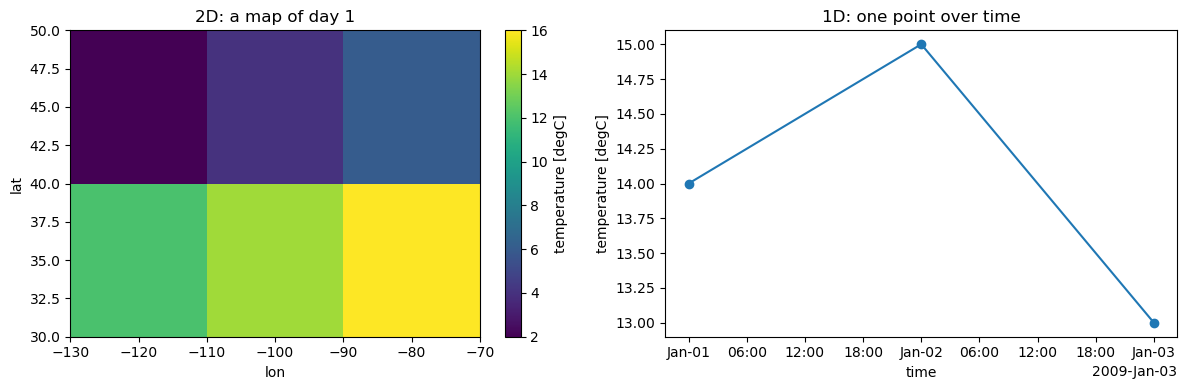

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
toy.isel(time=0).plot(ax=axes[0])
axes[0].set_title("2D: a map of day 1")
toy.sel(lat=35.0, lon=-100.0).plot(ax=axes[1], marker="o")
axes[1].set_title("1D: one point over time")
plt.tight_layout()
plt.show()

## 4. Open the ERA5 temperature data

The temperature is in six files, one per two months. `xr.open_mfdataset` ("multi-file dataset") opens them all as one `Dataset`. `combine="by_coords"` tells it to join them in order of their time coordinate.

The data is **not read into memory yet**. xarray uses a library called *dask* to load only what each calculation needs. That's why opening is fast, and why the summary below says `dask.array`.

In [8]:
temp_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "*2m_temperature*.nc")))
print(len(temp_files), "temperature files")

ds_temp = xr.open_mfdataset(temp_files, combine="by_coords")
ds_temp

12 temperature files


<xarray.Dataset> Size: 73MB
Dimensions:     (valid_time: 730, latitude: 105, longitude: 237)
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Data variables:
    t2m         (valid_time, latitude, longitude) float32 73MB dask.array<chunksize=(59, 105, 237), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-20T19:39 GRIB to CDM+CF via cfgrib-0.9.1...

Compare this with the toy example. The dimensions are `valid_time`, `latitude` and `longitude`. There is one data variable, `t2m`. `number` is a leftover coordinate from ERA5's ensemble system; it is always 0 here and you can ignore it.

In [9]:
list(ds_temp.data_vars)

['t2m']

In [10]:
T2M = ds_temp["t2m"]    # take the DataArray out of the Dataset
T2M

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<concatenate, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [11]:
print("Units:    ", T2M.attrs.get("units"))
print("Long name:", T2M.attrs.get("long_name"))

Units:     K
Long name: 2 metre temperature


ERA5 stores temperature in kelvin. Convert to Celsius, and set the units again, since arithmetic drops them:

In [12]:
T2M_C = T2M - 273.15
T2M_C.attrs["units"] = "degC"

How big is the dataset, and what does it cover?

In [13]:
print("Start date:", str(T2M_C.valid_time.values[0])[:10])
print("End date:  ", str(T2M_C.valid_time.values[-1])[:10])
print("Days:      ", T2M_C.sizes["valid_time"])
print()
print("Latitude points: ", T2M_C.sizes["latitude"],
      f"({float(T2M_C.latitude.min())} to {float(T2M_C.latitude.max())})")
print("Longitude points:", T2M_C.sizes["longitude"],
      f"({float(T2M_C.longitude.min())} to {float(T2M_C.longitude.max())})")

Start date: 2009-01-01
End date:   2010-12-31
Days:       730

Latitude points:  105 (24.0 to 50.0)
Longitude points: 237 (-125.0 to -66.0)


**Watch out:** the latitudes run from north to south (50 down to 24). A latitude slice must follow the same order: `slice(50, 24)` works, `slice(24, 50)` returns nothing.

In [14]:
T2M_C.coords

Coordinates:
    number      int64 8B 0
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31

## 5. Maps

`.isel(valid_time=0)` picks the first day. What's left is 2D, so `.plot()` draws a map.

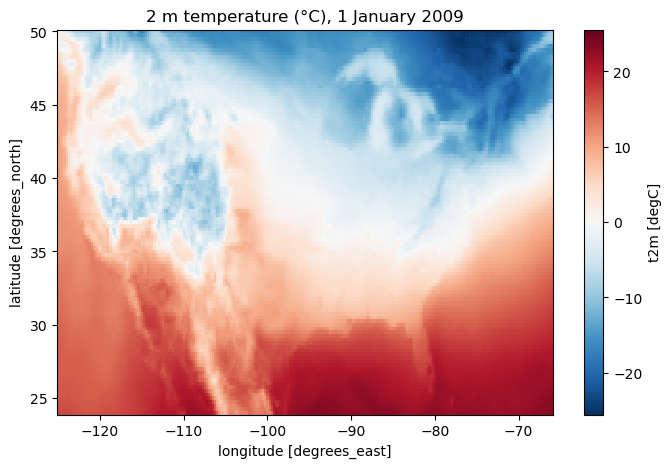

In [15]:
day0 = T2M_C.isel(valid_time=0)

day0.plot()
plt.title("2 m temperature (°C), 1 January 2009")
plt.show()

To compare two maps, give them the **same color scale** with `vmin` and `vmax`. Otherwise each map stretches its colors to its own range and they can't be compared.

`.sel(valid_time="2009-01-15")` selects by date. `method="nearest"` makes it pick the closest day if that exact date is missing.

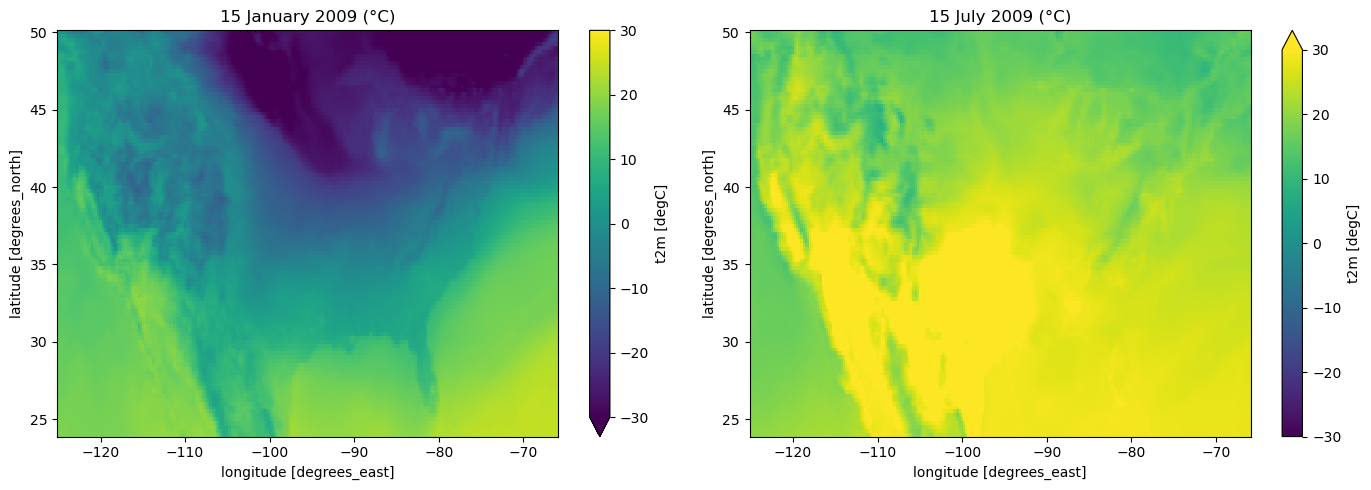

In [16]:
winter = T2M_C.sel(valid_time="2009-01-15", method="nearest")
summer = T2M_C.sel(valid_time="2009-07-15", method="nearest")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

winter.plot(ax=axes[0], vmin=-30, vmax=30)
axes[0].set_title("15 January 2009 (°C)")

summer.plot(ax=axes[1], vmin=-30, vmax=30)
axes[1].set_title("15 July 2009 (°C)")

plt.tight_layout()
plt.show()

## 6. A time series for one city

Selecting one latitude and one longitude leaves a 1D array over time. Chicago is at 41.9° N, 87.6° W. The grid has points every 0.25°, so `method="nearest"` picks the closest one.

Nearest grid point: 42.0 -87.5


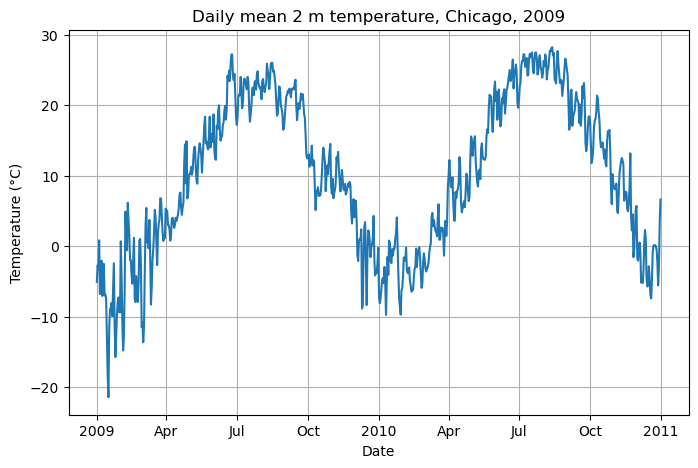

In [17]:
lat_chi = 41.9
lon_chi = -87.6

T_chi = T2M_C.sel(latitude=lat_chi, longitude=lon_chi, method="nearest")
print("Nearest grid point:", float(T_chi.latitude), float(T_chi.longitude))

T_chi.plot()
plt.title("Daily mean 2 m temperature, Chicago, 2009")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

In [18]:
print(f"Mean:               {float(T_chi.mean()):6.1f} °C")
print(f"Standard deviation: {float(T_chi.std()):6.1f} °C")
print(f"Min:                {float(T_chi.min()):6.1f} °C")
print(f"Max:                {float(T_chi.max()):6.1f} °C")

Mean:                 10.1 °C
Standard deviation:   10.9 °C
Min:                 -21.4 °C
Max:                  28.3 °C


`T_chi.mean()` returns a 0-dimensional `DataArray`. `float()` turns it into a plain number. This is also the moment dask actually reads the data from disk.

## 7. Precipitation

Same steps for total precipitation, variable `tp`. ERA5 stores precipitation as a depth of water in **metres**, so multiply by 1000 for millimetres.

In [19]:
precip_files = sorted(glob.glob(os.path.join(DATA_DIR, "*", "total_precipitation*.nc")))

ds_precip = xr.open_mfdataset(precip_files, combine="by_coords")
P = ds_precip["tp"]
print("Units in the file:", P.attrs.get("units"))

P_mm = P * 1000
P_mm.attrs["units"] = "mm/day"

Units in the file: m


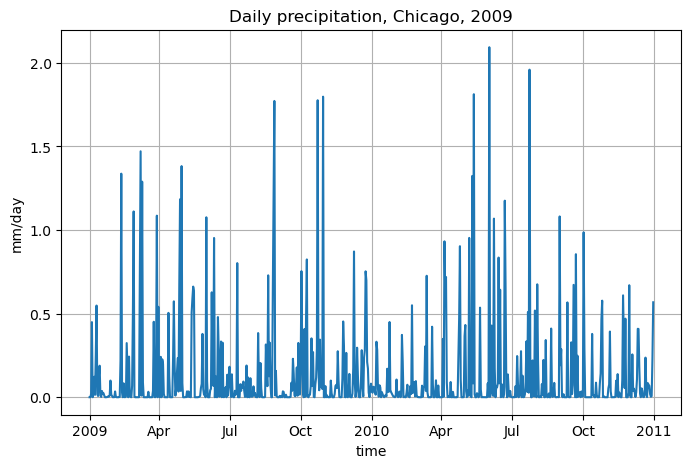

In [20]:
P_chi = P_mm.sel(latitude=lat_chi, longitude=lon_chi, method="nearest")

P_chi.plot()
plt.title("Daily precipitation, Chicago, 2009")
plt.ylabel("mm/day")
plt.grid(True)
plt.show()

### Check the units

Units are easy to get wrong, so check them against something you know. Chicago gets roughly 900 to 1,000 mm of precipitation in a year. Add up the daily values:

In [21]:
print(f"Total for 2009: {float(P_chi.sum()):.0f} mm")

Total for 2009: 97 mm


If the total is close to 900–1,000 mm, the values really are mm per day. If it's about 24 times smaller, each value is the *average hourly* amount for that day (the daily-mean files average ERA5's hourly values), and the daily total is 24 times larger.

**Question:** which is it? Fix `P_mm` above if needed, and rerun this section.

## 8. All the variables together

`open_mfdataset` can open every file at once. With `combine="by_coords"`, it joins the files along time *and* merges the five variables into one `Dataset` on the same grid. (`compat="no_conflicts"` only silences a warning from recent versions of xarray about a future change in how files are merged.)

In [22]:
ds = xr.open_mfdataset(all_files, combine="by_coords", compat="no_conflicts")
for name, var in ds.data_vars.items():
    print(f"{name:5s} {var.attrs.get('long_name', '')} ({var.attrs.get('units', '')})")

u10   10 metre U wind component (m s**-1)
v10   10 metre V wind component (m s**-1)
t2m   2 metre temperature (K)
msl   Mean sea level pressure (Pa)
tp    Total precipitation (m)


### Wind speed

ERA5 gives the wind as two components: `u10` (west to east) and `v10` (south to north), in m/s. The speed is $\sqrt{u^2 + v^2}$. NumPy functions work directly on `DataArray`s and keep the coordinates:

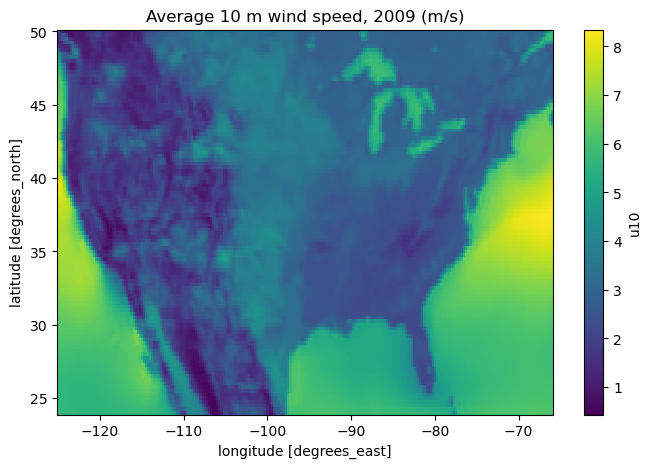

In [23]:
wind_speed = np.hypot(ds["u10"], ds["v10"])    # same as sqrt(u**2 + v**2)
wind_speed.attrs["units"] = "m/s"

wind_speed.mean(dim="valid_time").plot(cmap="viridis")
plt.title("Average 10 m wind speed, 2009 (m/s)")
plt.show()

### Pressure and wind on one day

Sea-level pressure (`msl`, in pascals; 100 Pa = 1 hPa) as a map, with wind arrows on top. Plotting an arrow at every grid point would be unreadable, so `.isel(..., slice(None, None, 8))` keeps every 8th point.

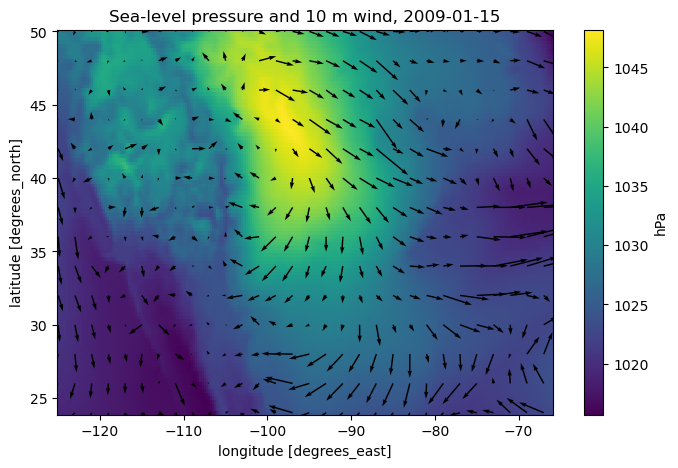

In [24]:
day = "2009-01-15"
msl_hPa = ds["msl"].sel(valid_time=day) / 100
wind = ds[["u10", "v10"]].sel(valid_time=day).isel(
    latitude=slice(None, None, 8), longitude=slice(None, None, 8))

msl_hPa.plot(cmap="viridis", cbar_kwargs={"label": "hPa"})
plt.quiver(wind["longitude"], wind["latitude"], wind["u10"], wind["v10"])
plt.title(f"Sea-level pressure and 10 m wind, {day}")
plt.show()

### Monthly averages

`.resample(valid_time="1MS")` groups the days into calendar months ("MS" = month start), like pandas. Follow it with a reduction such as `.mean()`.

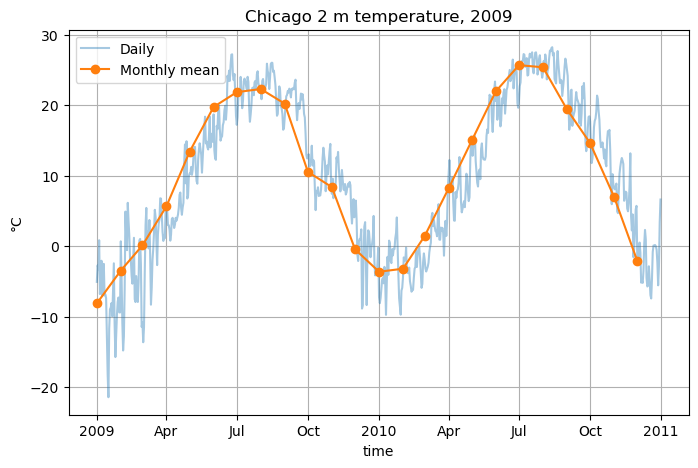

In [25]:
T_chi_monthly = T_chi.resample(valid_time="1MS").mean()

T_chi.plot(alpha=0.4, label="Daily")
T_chi_monthly.plot(marker="o", label="Monthly mean")
plt.title("Chicago 2 m temperature, 2009")
plt.ylabel("°C")
plt.legend()
plt.grid(True)
plt.show()

`.groupby("valid_time.month")` groups by month number instead. Here it gives an average map for each month, and we subtract January from July:

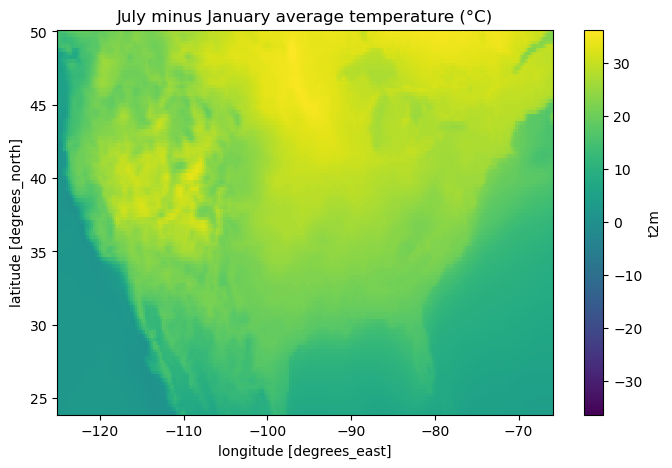

In [26]:
T_by_month = T2M_C.groupby("valid_time.month").mean()
(T_by_month.sel(month=7) - T_by_month.sel(month=1)).plot(cmap="viridis")
plt.title("July minus January average temperature (°C)")
plt.show()

**Question:** where is the seasonal swing smallest? Why?

### Averages over a region

To average over an area, select it with slices and take the mean over latitude and longitude. One subtlety: grid cells get smaller toward the poles, so each cell should count in proportion to $\cos(\text{latitude})$. xarray's `.weighted()` does this.

Here, a box around the Great Plains. Remember that latitude runs north to south, so the slice does too:

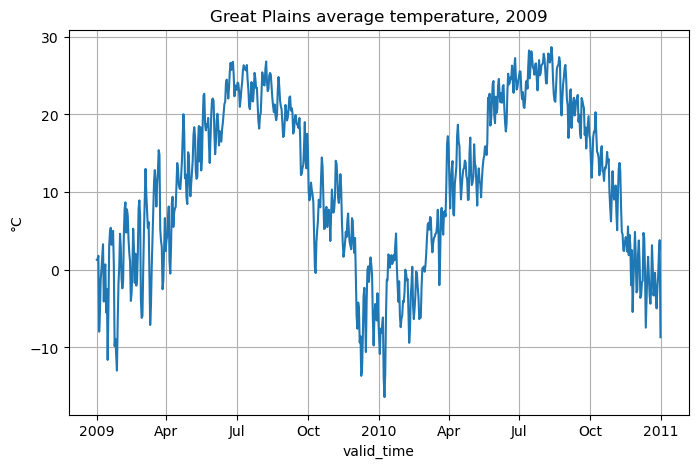

In [27]:
box = T2M_C.sel(latitude=slice(45, 35), longitude=slice(-105, -95))
weights = np.cos(np.deg2rad(box["latitude"]))

plains = box.weighted(weights).mean(dim=["latitude", "longitude"])

plains.plot()
plt.title("Great Plains average temperature, 2009")
plt.ylabel("°C")
plt.grid(True)
plt.show()

## 9. From xarray to pandas

Most machine-learning tools want a table: one row per example, one column per feature. `.to_dataframe()` turns a `DataArray` or `Dataset` into a pandas `DataFrame`, with one row per combination of coordinates.

Here, one row per day for Chicago, with all five variables as columns:

In [28]:
chi = ds.sel(latitude=lat_chi, longitude=lon_chi, method="nearest")
df_chi = chi.to_dataframe().drop(columns=["latitude", "longitude", "number"])

df_chi["t2m"] = df_chi["t2m"] - 273.15     # kelvin to Celsius
df_chi["wind_speed"] = np.hypot(df_chi["u10"], df_chi["v10"])
df_chi.head()

,u10,v10,t2m,msl,tp,wind_speed
valid_time,,,,,,
2009-01-01,0.344084,6.491430,-5.037201,102295.789062,0.000000e+00,6.500543
2009-01-02,5.421830,0.810517,-2.697693,101129.437500,1.986822e-08,5.482078
2009-01-03,-4.608213,-0.156748,-3.250793,101812.195312,2.036492e-05,4.610878
2009-01-04,0.049600,0.991480,0.868103,101455.789062,4.491806e-04,0.992720
2009-01-05,4.712213,-0.295123,-6.765900,102514.710938,0.000000e+00,4.721446


In [29]:
df_chi.describe().round(2)

,u10,v10,t2m,msl,tp,wind_speed
count,730.00,730.00,730.00,730.00,730.0,730.00
mean,0.46,0.12,10.09,101638.20,0.0,4.82
std,3.55,3.99,10.90,721.17,0.0,2.33
min,-9.71,-13.47,-21.40,98848.79,0.0,0.42
25%,-2.07,-2.66,0.96,101181.52,0.0,3.07
50%,0.41,-0.01,10.26,101628.04,0.0,4.50
75%,2.79,3.07,20.32,102075.10,0.0,6.40
max,11.77,10.40,28.25,104086.81,0.0,14.32


From here it's the same pandas you used with the Mauna Loa data in Week 2, and the same scikit-learn and PyTorch from Weeks 3 and 4.

Be careful with the size: the full grid is 365 × 105 × 237 ≈ 9 million rows per variable. Select a region or a set of points first.

## 10. Summary

| Task | Code |
|---|---|
| Open many files as one dataset | `xr.open_mfdataset(files, combine="by_coords")` |
| List the variables | `list(ds.data_vars)` |
| Take one variable | `ds["t2m"]` |
| Units and description | `da.attrs["units"]`, `da.attrs["long_name"]` |
| Size of each dimension | `da.sizes` |
| Select by position | `da.isel(valid_time=0)` |
| Select by label | `da.sel(valid_time="2009-07-15")` |
| Closest grid point | `da.sel(latitude=41.9, longitude=-87.6, method="nearest")` |
| A range | `da.sel(latitude=slice(45, 35))` (north to south) |
| Average over a dimension | `da.mean(dim="valid_time")` |
| Monthly means | `da.resample(valid_time="1MS").mean()` |
| Group by month | `da.groupby("valid_time.month").mean()` |
| Area-weighted mean | `da.weighted(np.cos(np.deg2rad(da.latitude))).mean(dim=["latitude", "longitude"])` |
| Plot | `da.plot()` |
| To pandas | `da.to_dataframe()` |

## 11. Things to try

1. **Another city.** Make the temperature and precipitation time series for Los Angeles (34.05° N, 118.25° W). How does its seasonal cycle compare with Chicago's?
2. **Hottest day.** On which day was the US-average temperature highest? Hint: average over latitude and longitude, then use `.idxmax()`.
3. **Wind and pressure.** Pick a stormy day (large precipitation over a big area) and plot pressure with wind arrows. Do the winds circle the low-pressure center?
4. **Toward a project.** Could you predict tomorrow's temperature in Chicago from today's five variables? Build the table with `.to_dataframe()`, add a column with tomorrow's temperature using `.shift(-1)`, and try a linear regression.

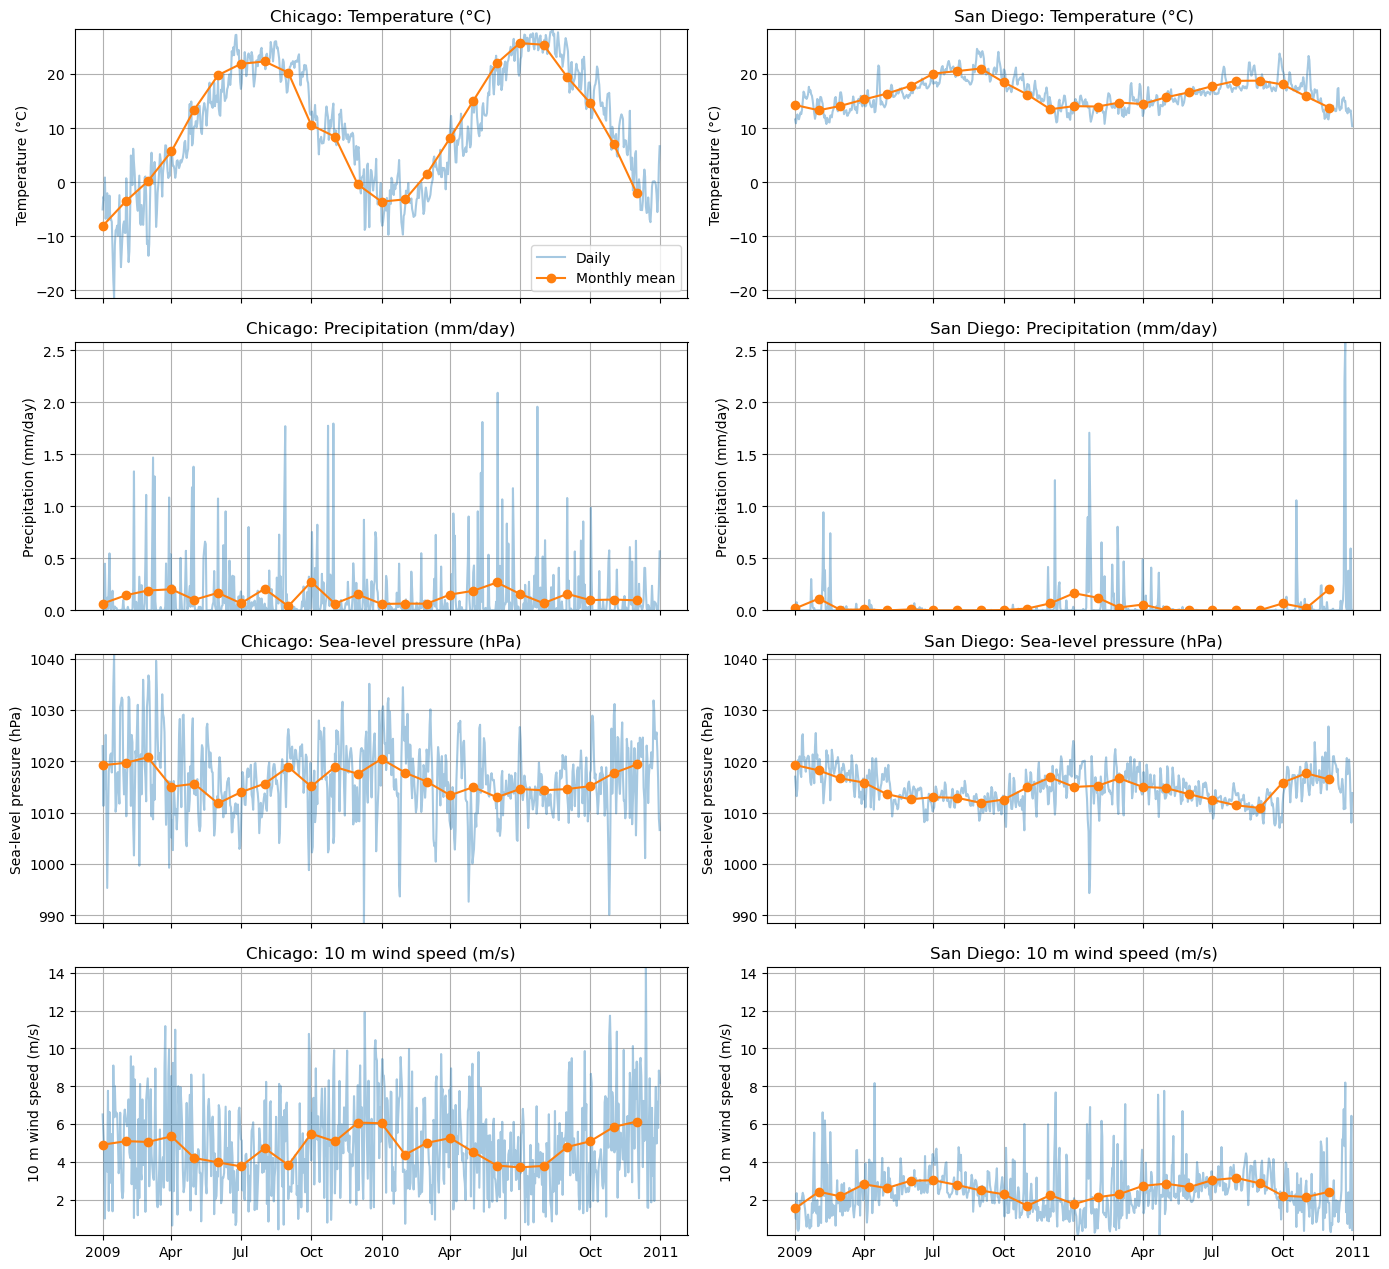

In [30]:
# Weather comparison: How do temperature, precipitation, air pressure, and wind speed differ between Chicago and San Diego over time?
cities = {
    "Chicago":   (41.9, -87.6),
    "San Diego": (32.7, -117.2),
}

def at(da, lat, lon):
    return da.sel(latitude=lat, longitude=lon, method="nearest")

# One DataArray per variable
variables = {
    "Temperature (°C)":         T2M_C,
    "Precipitation (mm/day)":   P_mm,
    "Sea-level pressure (hPa)": ds["msl"] / 100,
    "10 m wind speed (m/s)":    np.hypot(ds["u10"], ds["v10"]),
}

fig, axes = plt.subplots(len(variables), 2, figsize=(14, 3.2 * len(variables)), sharex=True)

for row, (label, da) in enumerate(variables.items()):
    # Same y-range in both columns so the cities are comparable
    series = {name: at(da, lat, lon).compute() for name, (lat, lon) in cities.items()}
    lo = min(float(s.min()) for s in series.values())
    hi = max(float(s.max()) for s in series.values())

    for col, (name, s) in enumerate(series.items()):
        ax = axes[row, col]
        s.plot(ax=ax, alpha=0.4, label="Daily")
        s.resample(valid_time="1MS").mean().plot(ax=ax, marker="o", label="Monthly mean")
        ax.set_ylim(lo, hi)
        ax.set_title(f"{name}: {label}")
        ax.set_xlabel("")
        ax.set_ylabel(label)
        ax.grid(True)
        if row == 0 and col == 0:
            ax.legend()

plt.tight_layout()
plt.show()

US-average hottest day: 2010-07-16  (25.2 °C)
Chicago    hottest day: 2010-08-13  (28.3 °C)
San Diego  hottest day: 2009-08-27  (24.6 °C)


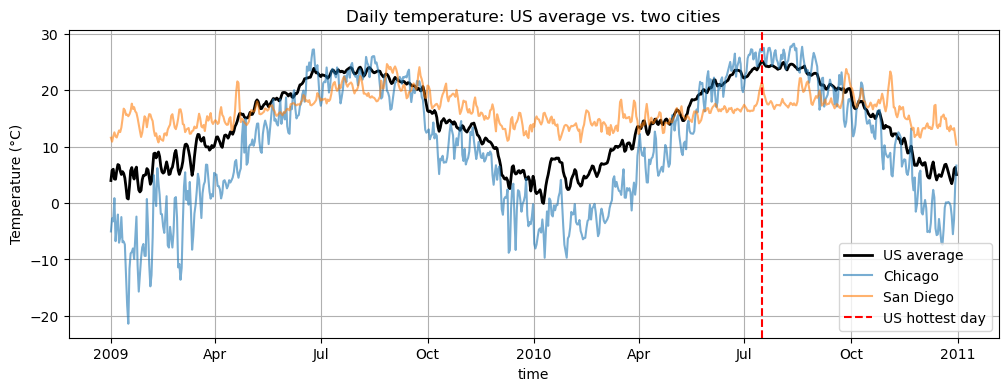

In [31]:
# When was the study region warmest on average, and how did Chicago and San Diego compare?
cities = {
    "Chicago":   (41.9, -87.6),
    "San Diego": (32.7, -117.2),
}

# US-average temperature each day, weighting cells by cos(latitude)
w = np.cos(np.deg2rad(T2M_C["latitude"]))
T_us = T2M_C.weighted(w).mean(dim=["latitude", "longitude"]).compute()

hot_day = T_us.idxmax("valid_time")
print(f"US-average hottest day: {str(hot_day.values)[:10]}  ({float(T_us.max()):.1f} °C)")

# Hottest day for each city
for name, (lat, lon) in cities.items():
    T_city = T2M_C.sel(latitude=lat, longitude=lon, method="nearest").compute()
    print(f"{name:10s} hottest day: {str(T_city.idxmax('valid_time').values)[:10]}  ({float(T_city.max()):.1f} °C)")

# Plot: US average with both cities, hottest day marked
fig, ax = plt.subplots(figsize=(12, 4))
T_us.plot(ax=ax, color="black", lw=2, label="US average")
for name, (lat, lon) in cities.items():
    T2M_C.sel(latitude=lat, longitude=lon, method="nearest").plot(ax=ax, alpha=0.6, label=name)
ax.axvline(hot_day.values, color="red", ls="--", label="US hottest day")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily temperature: US average vs. two cities")
ax.legend()
ax.grid(True)
plt.show()


Stormiest day: 2010-03-13  (0.2 mm/day US average)


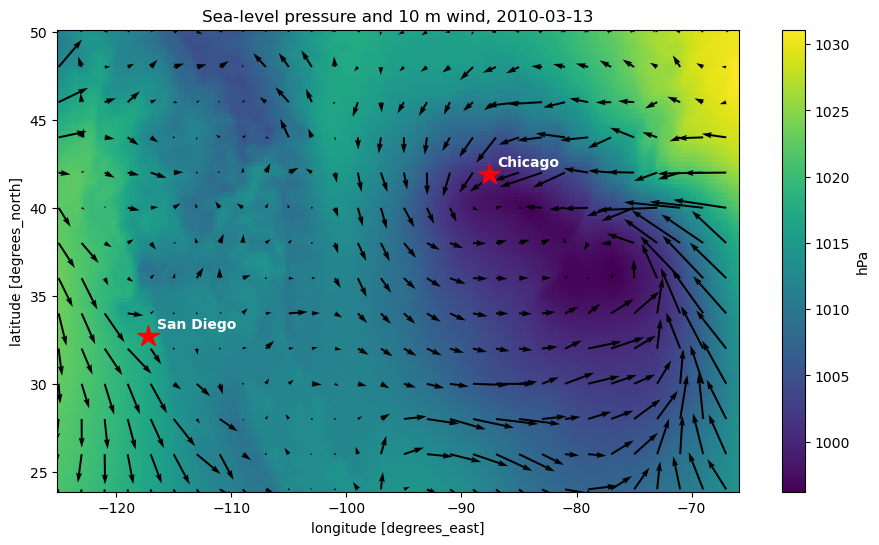

In [ ]:
# Stormy day = the day with the most US-average precipitation
# Q: On the day with the highest average precipitation across the study region, how do wind patterns relate to areas of high and low pressure?
P_us = P_mm.weighted(w).mean(dim=["latitude", "longitude"]).compute()
storm_day = str(P_us.idxmax("valid_time").values)[:10]
print(f"Stormiest day: {storm_day}  ({float(P_us.max()):.1f} mm/day US average)")

msl_hPa = ds["msl"].sel(valid_time=storm_day) / 100
wind = ds[["u10", "v10"]].sel(valid_time=storm_day).isel(
    latitude=slice(None, None, 8), longitude=slice(None, None, 8))

fig, ax = plt.subplots(figsize=(11, 6))
msl_hPa.plot(ax=ax, cmap="viridis", cbar_kwargs={"label": "hPa"})
ax.quiver(wind["longitude"], wind["latitude"], wind["u10"], wind["v10"])
for name, (lat, lon) in cities.items():
    ax.plot(lon, lat, "r*", ms=16)
    ax.annotate(name, (lon, lat), xytext=(6, 6), textcoords="offset points",
                color="white", weight="bold")
ax.set_title(f"Sea-level pressure and 10 m wind, {storm_day}")
plt.show()


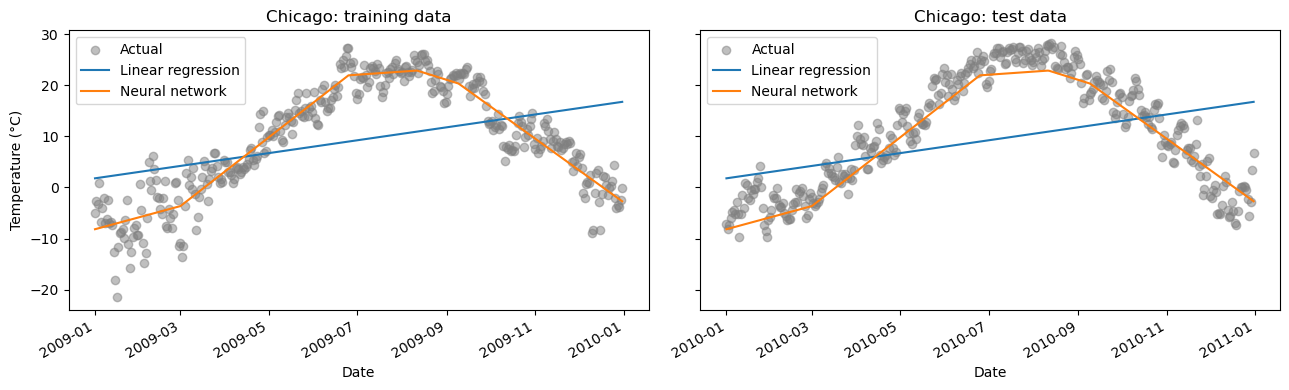

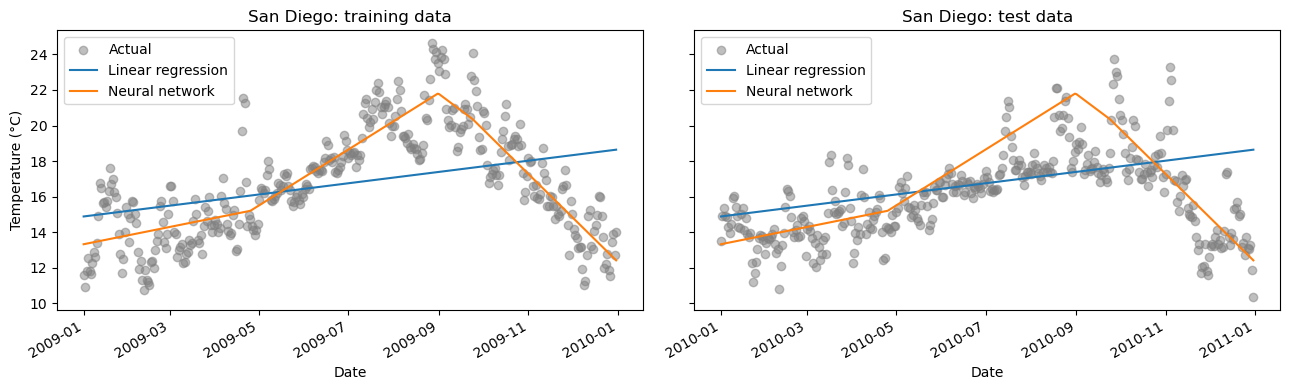

     City             Model  Training MAE (C)  Test MAE (C)  Training RMSE (C)  Test RMSE (C)  Training R2  Test R2
  Chicago Linear regression              8.35          8.91               9.83          10.60         0.16     0.07
  Chicago    Neural network              2.63          2.92               3.46           3.55         0.90     0.90
San Diego Linear regression              2.29          1.68               2.87           2.37         0.13     0.01
San Diego    Neural network              1.20          1.48               1.51           1.86         0.76     0.39


In [34]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, r2_score

cities = {
    "Chicago": (41.9, -87.6),
    "San Diego": (32.7, -117.2)
}

results = []

for city in cities:

    latitude, longitude = cities[city]

    temperature = T2M_C.sel(
        latitude=latitude,
        longitude=longitude,
        method="nearest"
    ).to_series()

    data = pd.DataFrame({"temperature": temperature})
    data = data.dropna().sort_index()
    data["day_of_year"] = data.index.dayofyear

    train = data.loc["2009"]
    test = data.loc["2010"]

    X_train = train[["day_of_year"]]
    y_train = train["temperature"]

    X_test = test[["day_of_year"]]
    y_test = test["temperature"]

    linear = LinearRegression()
    linear.fit(X_train, y_train)

    network = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(10,),
            activation="relu",
            solver="lbfgs",
            max_iter=5000,
            random_state=0
        )
    )

    neural = TransformedTargetRegressor(
        regressor=network,
        transformer=StandardScaler()
    )

    neural.fit(X_train, y_train)

    linear_train = linear.predict(X_train)
    linear_test = linear.predict(X_test)

    neural_train = neural.predict(X_train)
    neural_test = neural.predict(X_test)

    results.append([
        city,
        "Linear regression",
        mean_absolute_error(y_train, linear_train),
        mean_absolute_error(y_test, linear_test),
        np.sqrt(mean_squared_error(y_train, linear_train)),
        np.sqrt(mean_squared_error(y_test, linear_test)),
        r2_score(y_train, linear_train),
        r2_score(y_test, linear_test)
    ])

    results.append([
        city,
        "Neural network",
        mean_absolute_error(y_train, neural_train),
        mean_absolute_error(y_test, neural_test),
        np.sqrt(mean_squared_error(y_train, neural_train)),
        np.sqrt(mean_squared_error(y_test, neural_test)),
        r2_score(y_train, neural_train),
        r2_score(y_test, neural_test)
    ])

    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

    axes[0].scatter(
        train.index,
        y_train,
        color="gray",
        alpha=0.5,
        label="Actual"
    )

    axes[0].plot(
        train.index,
        linear_train,
        label="Linear regression"
    )

    axes[0].plot(
        train.index,
        neural_train,
        label="Neural network"
    )

    axes[0].set_title(city + ": training data")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Temperature (°C)")
    axes[0].legend()

    axes[1].scatter(
        test.index,
        y_test,
        color="gray",
        alpha=0.5,
        label="Actual"
    )

    axes[1].plot(
        test.index,
        linear_test,
        label="Linear regression"
    )

    axes[1].plot(
        test.index,
        neural_test,
        label="Neural network"
    )

    axes[1].set_title(city + ": test data")
    axes[1].set_xlabel("Date")
    axes[1].legend()

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

scores = pd.DataFrame(
    results,
    columns=[
        "City",
        "Model",
        "Training MAE (C)",
        "Test MAE (C)",
        "Training RMSE (C)",
        "Test RMSE (C)",
        "Training R2",
        "Test R2"
    ]
)

print(scores.round(2).to_string(index=False))

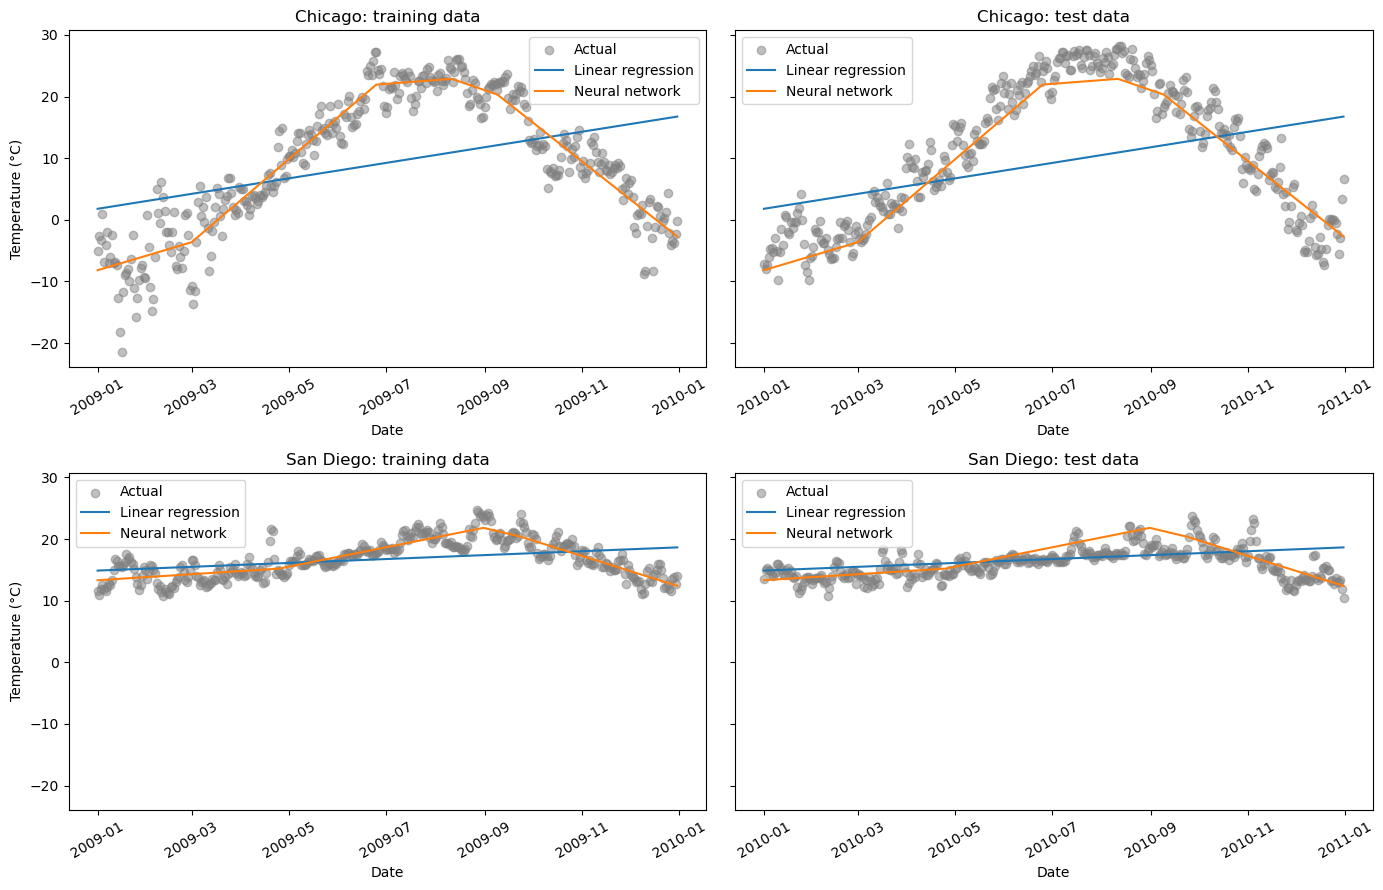

     City             Model  Training MAE (C)  Test MAE (C)  Training RMSE (C)  Test RMSE (C)  Training R2  Test R2
  Chicago Linear regression              8.35          8.91               9.83          10.60         0.16     0.07
  Chicago    Neural network              2.63          2.92               3.46           3.55         0.90     0.90
San Diego Linear regression              2.29          1.68               2.87           2.37         0.13     0.01
San Diego    Neural network              1.20          1.48               1.51           1.86         0.76     0.39


In [35]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, r2_score

cities = {
    "Chicago": (41.9, -87.6),
    "San Diego": (32.7, -117.2)
}

results = []

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

for row, city in enumerate(cities):

    latitude, longitude = cities[city]

    temperature = T2M_C.sel(
        latitude=latitude,
        longitude=longitude,
        method="nearest"
    ).to_series()

    data = pd.DataFrame({"temperature": temperature})
    data = data.dropna().sort_index()
    data["day_of_year"] = data.index.dayofyear

    train = data.loc["2009"]
    test = data.loc["2010"]

    X_train = train[["day_of_year"]]
    y_train = train["temperature"]

    X_test = test[["day_of_year"]]
    y_test = test["temperature"]

    linear = LinearRegression()
    linear.fit(X_train, y_train)

    network = make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(10,),
            activation="relu",
            solver="lbfgs",
            max_iter=5000,
            random_state=0
        )
    )

    neural = TransformedTargetRegressor(
        regressor=network,
        transformer=StandardScaler()
    )

    neural.fit(X_train, y_train)

    linear_train = linear.predict(X_train)
    linear_test = linear.predict(X_test)

    neural_train = neural.predict(X_train)
    neural_test = neural.predict(X_test)

    results.append([
        city,
        "Linear regression",
        mean_absolute_error(y_train, linear_train),
        mean_absolute_error(y_test, linear_test),
        np.sqrt(mean_squared_error(y_train, linear_train)),
        np.sqrt(mean_squared_error(y_test, linear_test)),
        r2_score(y_train, linear_train),
        r2_score(y_test, linear_test)
    ])

    results.append([
        city,
        "Neural network",
        mean_absolute_error(y_train, neural_train),
        mean_absolute_error(y_test, neural_test),
        np.sqrt(mean_squared_error(y_train, neural_train)),
        np.sqrt(mean_squared_error(y_test, neural_test)),
        r2_score(y_train, neural_train),
        r2_score(y_test, neural_test)
    ])

    ax_train = axes[row, 0]
    ax_test = axes[row, 1]

    ax_train.scatter(
        train.index,
        y_train,
        color="gray",
        alpha=0.5,
        label="Actual"
    )

    ax_train.plot(
        train.index,
        linear_train,
        label="Linear regression"
    )

    ax_train.plot(
        train.index,
        neural_train,
        label="Neural network"
    )

    ax_train.set_title(city + ": training data")
    ax_train.set_xlabel("Date")
    ax_train.set_ylabel("Temperature (°C)")
    ax_train.legend()
    ax_train.tick_params(axis="x", labelrotation=30)

    ax_test.scatter(
        test.index,
        y_test,
        color="gray",
        alpha=0.5,
        label="Actual"
    )

    ax_test.plot(
        test.index,
        linear_test,
        label="Linear regression"
    )

    ax_test.plot(
        test.index,
        neural_test,
        label="Neural network"
    )

    ax_test.set_title(city + ": test data")
    ax_test.set_xlabel("Date")
    ax_test.legend()
    ax_test.tick_params(axis="x", labelrotation=30)

plt.tight_layout()
plt.show()

scores = pd.DataFrame(
    results,
    columns=[
        "City",
        "Model",
        "Training MAE (C)",
        "Test MAE (C)",
        "Training RMSE (C)",
        "Test RMSE (C)",
        "Training R2",
        "Test R2"
    ]
)

print(scores.round(2).to_string(index=False))

In [ ]:
# held out the last 20% of days in 2009 for validation(not ideal for the purposes of this project)
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_squared_error, r2_score

cities = {
    "Chicago": (41.9, -87.6),
    "San Diego": (32.7, -117.2)
}

validation_results = []
best_neurons = {}

for city in cities:

    latitude, longitude = cities[city]

    temperature = T2M_C.sel(
        latitude=latitude,
        longitude=longitude,
        method="nearest"
    ).to_series()

    data = pd.DataFrame({"temperature": temperature})
    data = data.dropna().sort_index()
    data["day_of_year"] = data.index.dayofyear

    development = data.loc["2009"]

    cut = int(0.8 * len(development))
    train = development.iloc[:cut]
    validation = development.iloc[cut:]

    X_train = train[["day_of_year"]]
    y_train = train["temperature"]

    X_validation = validation[["day_of_year"]]
    y_validation = validation["temperature"]

    best_error = float("inf")

    for neurons in [5, 10, 20]:

        network = make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(neurons,),
                activation="relu",
                solver="lbfgs",
                max_iter=5000,
                random_state=0
            )
        )

        neural = TransformedTargetRegressor(
            regressor=network,
            transformer=StandardScaler()
        )

        neural.fit(X_train, y_train)

        train_prediction = neural.predict(X_train)
        validation_prediction = neural.predict(X_validation)

        validation_error = mean_absolute_error(
            y_validation, validation_prediction
        )

        validation_results.append([
            city,
            neurons,
            mean_absolute_error(y_train, train_prediction),
            validation_error,
            np.sqrt(mean_squared_error(y_train, train_prediction)),
            np.sqrt(mean_squared_error(y_validation, validation_prediction)),
            r2_score(y_train, train_prediction),
            r2_score(y_validation, validation_prediction)
        ])

        if validation_error < best_error:
            best_error = validation_error
            best_neurons[city] = neurons

validation_scores = pd.DataFrame(
    validation_results,
    columns=[
        "City",
        "Neurons",
        "Training MAE (C)",
        "Validation MAE (C)",
        "Training RMSE (C)",
        "Validation RMSE (C)",
        "Training R2",
        "Validation R2"
    ]
)

print(validation_scores.round(2).to_string(index=False))

print("\nSelected by lowest validation MAE:")

for city in best_neurons:
    print(city, ":", best_neurons[city], "neurons")

     City  Neurons  Training MAE (C)  Validation MAE (C)  Training RMSE (C)  Validation RMSE (C)  Training R2  Validation R2
  Chicago        5              2.48               13.52               3.35                14.24         0.91          -5.13
  Chicago       10              2.48               18.09               3.36                18.92         0.91          -9.82
  Chicago       20              2.18               10.88               3.08                11.50         0.93          -3.00
San Diego        5              1.23                3.99               1.55                 4.63         0.76          -3.36
San Diego       10              1.05                1.07               1.39                 1.28         0.81           0.67
San Diego       20              0.90               31.65               1.23                37.12         0.85        -279.95

Selected by lowest validation MAE:
Chicago : 20 neurons
San Diego : 10 neurons


Nearest ERA5 grid points: {'Chicago': (42.0, -87.5), 'San Diego': (32.75, -117.25)}


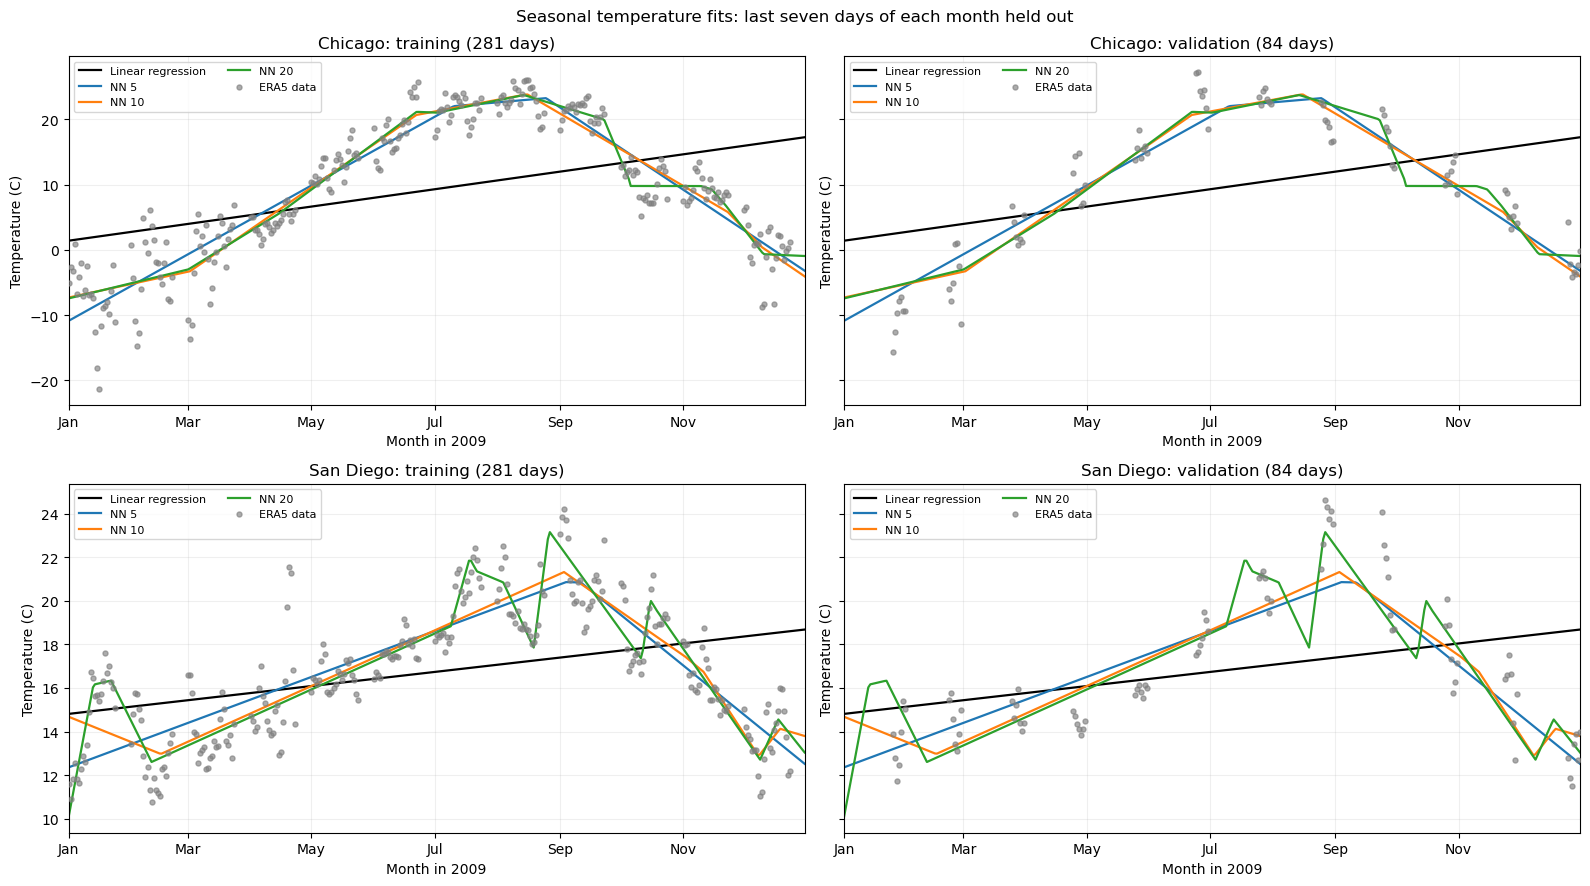

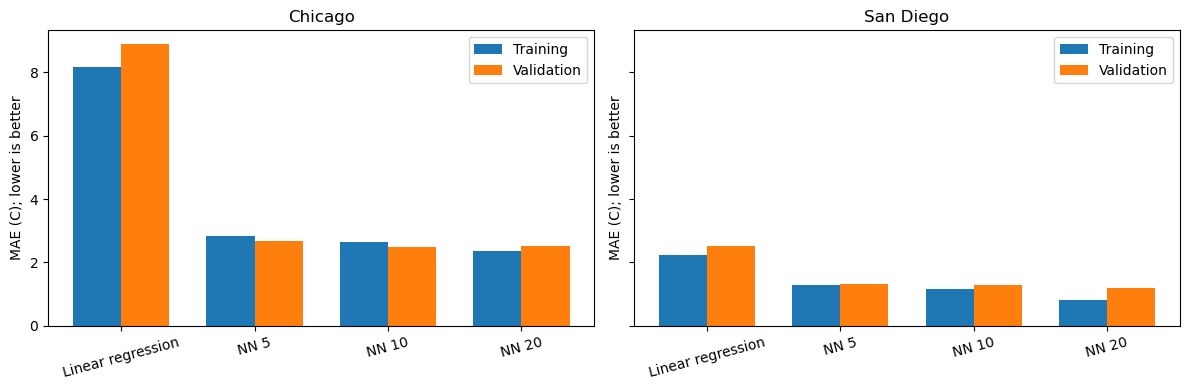


scikit-learn 1.7.2; random_state=0
Training: 281 days; validation: 84 days; 2010 not used.

     City             Model  Neurons  Parameters  Training MAE (C)  Training RMSE (C)  Training R2  Validation MAE (C)  Validation RMSE (C)  Validation R2  MAE gap (C)  Optimizer iterations  Convergence warning
  Chicago Linear regression        0           2             8.178              9.646        0.184               8.886               10.456          0.090        0.708                   NaN                False
  Chicago              NN 5        5          16             2.840              3.735        0.878               2.686                3.471          0.900       -0.154                  38.0                False
  Chicago             NN 10       10          31             2.649              3.512        0.892               2.498                3.257          0.912       -0.151                 248.0                False
  Chicago             NN 20       20          61             2.

In [2]:
"""Compare 5-, 10-, and 20-neuron seasonal temperature models in 2009.

Run from a notebook: %run month_end_validation.py
Or paste into a notebook cell whose working folder contains data/.
Or in Terminal: /opt/anaconda3/envs/290A/bin/python month_end_validation.py

The final seven calendar days of every month are validation data. No 2010
files are loaded. Outputs are saved beside this script in month_end_results/.
"""

from pathlib import Path
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xarray as xr
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


# Notebook cells do not define __file__, so use their working folder instead.
PROJECT_DIR = (
    Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
)
CITIES = {"Chicago": (41.9, -87.6), "San Diego": (32.7, -117.2)}
WIDTHS = [5, 10, 20]
RANDOM_STATE = 0
COLORS = {"Linear regression": "black", "NN 5": "tab:blue",
          "NN 10": "tab:orange", "NN 20": "tab:green"}


def load_temperatures(data_dir):
    """Read only the two nearest city grid points from the 2009 files."""
    files = sorted(Path(data_dir).glob("2009_*/*2m_temperature*.nc"))
    if not files:
        raise FileNotFoundError(f"No 2009 temperature files found in {data_dir}")

    parts = {city: [] for city in CITIES}
    grid_points = {}
    for path in files:
        with xr.open_dataset(path) as dataset:
            if dataset["t2m"].attrs.get("units") != "K":
                raise ValueError(f"Expected temperature in kelvin: {path}")
            for city, (latitude, longitude) in CITIES.items():
                temperature = dataset["t2m"].sel(
                    latitude=latitude, longitude=longitude, method="nearest"
                )
                parts[city].append(temperature.to_series() - 273.15)
                grid_points[city] = (
                    float(temperature.latitude), float(temperature.longitude)
                )

    temperatures = pd.DataFrame({
        city: pd.concat(series).sort_index() for city, series in parts.items()
    })
    temperatures.index.name = "date"
    print("Nearest ERA5 grid points:", grid_points)
    return temperatures


def run_comparison(temperatures, output_dir):
    """Fit every model on the same dates; return metrics and predictions."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    temperatures = temperatures.loc["2009-01-01":"2009-12-31", list(CITIES)]
    expected_dates = pd.date_range("2009-01-01", "2009-12-31")
    if not temperatures.index.equals(expected_dates):
        raise ValueError("Expected exactly one ordered observation per day in 2009.")
    if not np.isfinite(temperatures.to_numpy()).all():
        raise ValueError("City temperatures must contain no missing or infinite values.")

    dates = temperatures.index
    # Example: January 25-31 and February 22-28 are validation dates.
    validation_mask = dates.day > dates.days_in_month - 7
    training_mask = ~validation_mask
    assert training_mask.sum() == 281 and validation_mask.sum() == 84

    split = pd.DataFrame({
        "split": np.where(validation_mask, "Validation", "Training")
    }, index=dates)
    split.index.name = "date"
    split.to_csv(output_dir / "split_dates.csv")
    split_summary = []
    for month in range(1, 13):
        held_out = dates[validation_mask & (dates.month == month)]
        assert len(held_out) == 7
        split_summary.append({
            "Month": held_out[0].strftime("%B"),
            "Training days": int(((dates.month == month) & training_mask).sum()),
            "Validation days": len(held_out),
            "Validation start": held_out[0].date().isoformat(),
            "Validation end": held_out[-1].date().isoformat(),
        })
    pd.DataFrame(split_summary).to_csv(output_dir / "monthly_split.csv", index=False)

    # The only input is the calendar day, not today's weather measurements.
    X = dates.dayofyear.to_numpy().reshape(-1, 1)
    rows, prediction_rows, monthly_rows = [], [], []
    fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey="row")

    for city_index, city in enumerate(CITIES):
        y = temperatures[city].to_numpy()
        models = {"Linear regression": LinearRegression()}
        for neurons in WIDTHS:
            models[f"NN {neurons}"] = TransformedTargetRegressor(
                regressor=make_pipeline(
                    StandardScaler(),
                    MLPRegressor(
                        hidden_layer_sizes=(neurons,),
                        activation="relu",
                        solver="lbfgs",
                        alpha=0.0001,
                        max_iter=5000,
                        max_fun=15000,
                        early_stopping=False,
                        random_state=RANDOM_STATE,
                    ),
                ),
                transformer=StandardScaler(),
            )

        for name, model in models.items():
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                model.fit(X[training_mask], y[training_mask])
            fit_warnings = [str(w.message) for w in caught]
            for message in fit_warnings:
                warnings.warn(f"{city}, {name}: {message}")
            predictions = model.predict(X)
            is_network = name.startswith("NN")
            neurons = int(name.split()[1]) if is_network else 0
            row = {"City": city, "Model": name, "Neurons": neurons,
                   "Parameters": 3 * neurons + 1 if is_network else 2}
            for label, mask in [("Training", training_mask),
                                ("Validation", validation_mask)]:
                row[f"{label} MAE (C)"] = mean_absolute_error(y[mask], predictions[mask])
                row[f"{label} RMSE (C)"] = np.sqrt(mean_squared_error(y[mask], predictions[mask]))
                row[f"{label} R2"] = r2_score(y[mask], predictions[mask])
            row["MAE gap (C)"] = row["Validation MAE (C)"] - row["Training MAE (C)"]
            row["Optimizer iterations"] = (
                model.regressor_.named_steps["mlpregressor"].n_iter_ if is_network else np.nan
            )
            row["Convergence warning"] = any(
                issubclass(w.category, ConvergenceWarning) for w in caught
            )
            rows.append(row)
            prediction_rows.append(pd.DataFrame({
                "date": dates, "City": city, "Model": name,
                "Split": split["split"].to_numpy(),
                "Actual (C)": y, "Predicted (C)": predictions,
            }))
            for month in range(1, 13):
                mask = validation_mask & (dates.month == month)
                monthly_rows.append({
                    "City": city, "Model": name, "Month": month,
                    "Validation MAE (C)": mean_absolute_error(y[mask], predictions[mask]),
                })

            for column, mask in enumerate([training_mask, validation_mask]):
                ax = axes[city_index, column]
                # The smooth line is the fitted calendar curve; dots are scored data.
                ax.plot(dates, predictions, color=COLORS[name], label=name, linewidth=1.6)

        for column, (label, mask) in enumerate([
            ("Training", training_mask), ("Validation", validation_mask)
        ]):
            ax = axes[city_index, column]
            ax.scatter(dates[mask], y[mask], color="gray", s=13,
                       alpha=0.65, label="ERA5 data", zorder=3)
            ax.set_title(f"{city}: {label.lower()} ({mask.sum()} days)")
            ax.set_ylabel("Temperature (C)")
            ax.set_xlabel("Month in 2009")
            ax.set_xlim(dates[0], dates[-1])
            ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
            ax.grid(alpha=0.2)
            ax.legend(fontsize=8, ncol=2)

    fig.suptitle("Seasonal temperature fits: last seven days of each month held out")
    fig.tight_layout()
    fig.savefig(output_dir / "seasonal_fits.png", dpi=160)
    if plt.get_backend().lower() != "agg":
        plt.show()
    plt.close(fig)

    results = pd.DataFrame(rows)
    monthly_results = pd.DataFrame(monthly_rows)
    predictions = pd.concat(prediction_rows, ignore_index=True)
    results.to_csv(output_dir / "model_comparison.csv", index=False)
    monthly_results.to_csv(output_dir / "monthly_validation_mae.csv", index=False)
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    networks = results[results["Neurons"] > 0]
    best_indices = networks.groupby("City")["Validation MAE (C)"].idxmin()
    best_networks = networks.loc[best_indices].reset_index(drop=True)
    best_networks.to_csv(output_dir / "selected_networks.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, city in zip(axes, CITIES):
        city_results = results[results["City"] == city]
        positions = np.arange(len(city_results))
        ax.bar(positions - 0.18, city_results["Training MAE (C)"],
               width=0.36, label="Training")
        ax.bar(positions + 0.18, city_results["Validation MAE (C)"],
               width=0.36, label="Validation")
        ax.set_xticks(positions, city_results["Model"], rotation=15)
        ax.set_title(city)
        ax.set_ylabel("MAE (C); lower is better")
        ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / "training_validation_mae.png", dpi=160)
    if plt.get_backend().lower() != "agg":
        plt.show()
    plt.close(fig)

    print(f"\nscikit-learn {sklearn.__version__}; random_state={RANDOM_STATE}")
    print("Training: 281 days; validation: 84 days; 2010 not used.\n")
    print(results.round(3).to_string(index=False))
    print("\nPreferred network per city (lowest validation MAE):")
    print(best_networks[["City", "Neurons", "Validation MAE (C)"]].round(3).to_string(index=False))
    print(f"\nSaved outputs: {output_dir}")
    return results, best_networks, predictions, monthly_results


if __name__ == "__main__":
    city_temperatures = load_temperatures(PROJECT_DIR / "data")
    results, best_networks, predictions, monthly_results = run_comparison(
        city_temperatures, PROJECT_DIR / "month_end_results"
    )


The graph asks:
- Does adding more neurons improve temperature predictions?
- Does a better training fit also mean better performance on held-out data?
“For both cities, the neural networks captured the seasonal temperature pattern better than straight-line regression. Chicago’s 10-neuron network had the lowest validation MAE, about 2.50°C, although 20 neurons performed almost identically. San Diego’s 20-neuron network performed best, with an MAE of about 1.18°C.

Adding more neurons improved training performance, but did not always improve validation performance. We should choose the network using held-out data, rather than training results alone. These results concern missing temperatures within 2009, not future weather forecasts.”

The main limitation is that this tests filling gaps within 2009, so it does not establish future forecasting accuracy.
- Nearby days are related: Training days surround most held-out weeks. Similar weather on neighboring days can make validation easier.
- Only day of year is used: The model learns the seasonal pattern but lacks weather information needed to predict sudden temperature changes.
- Limited evidence: One year and one random seed cannot show whether the preferred network size is consistently best.
- Validation also selects the model: Because these scores determine the winning width, they are not an independent final test.
A stronger next step is to fix the network size, then evaluate it on an untouched year and repeat training with several random seeds.

In [4]:
from pathlib import Path
import xarray as xr

data_dir = Path("/Users/amirsh96/290A/Project 1/data")

temperature_files = sorted(
    data_dir.glob("2009_*/*2m_temperature*.nc")
)

if not temperature_files:
    raise FileNotFoundError(f"No 2009 temperature files found in {data_dir}")

temperature_parts = []

for file in temperature_files:
    with xr.open_dataset(file) as dataset:
        temperature_parts.append(dataset["t2m"].load())

T2M_C = (
    xr.concat(temperature_parts, dim="valid_time")
    .sortby("valid_time")
    - 273.15
)

T2M_C.attrs["units"] = "degC"

print("Loaded", T2M_C.sizes["valid_time"], "days of temperature data.")

Loaded 365 days of temperature data.


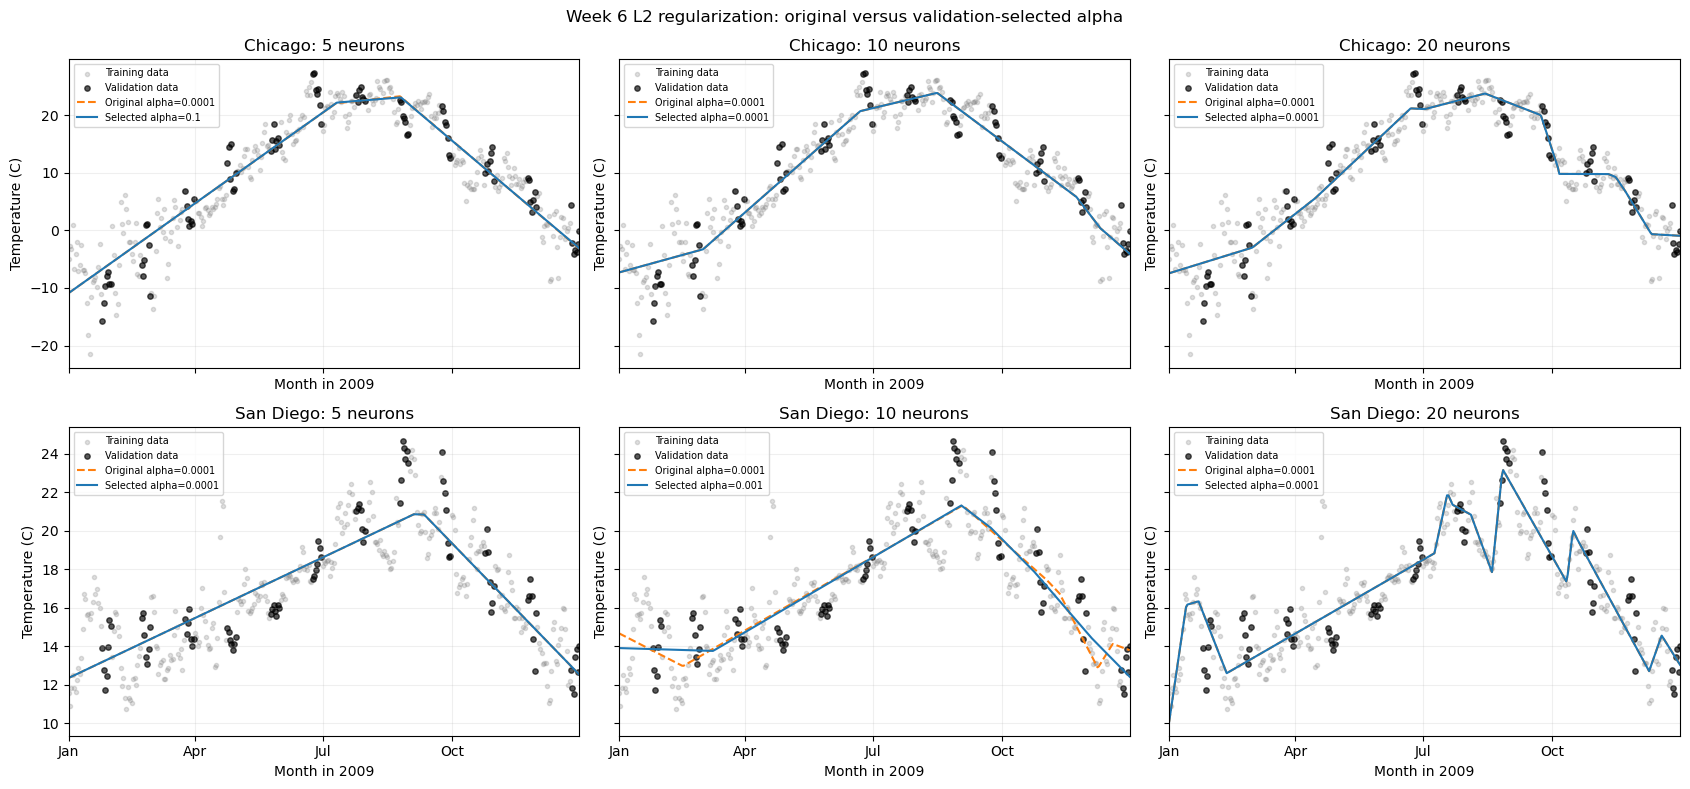

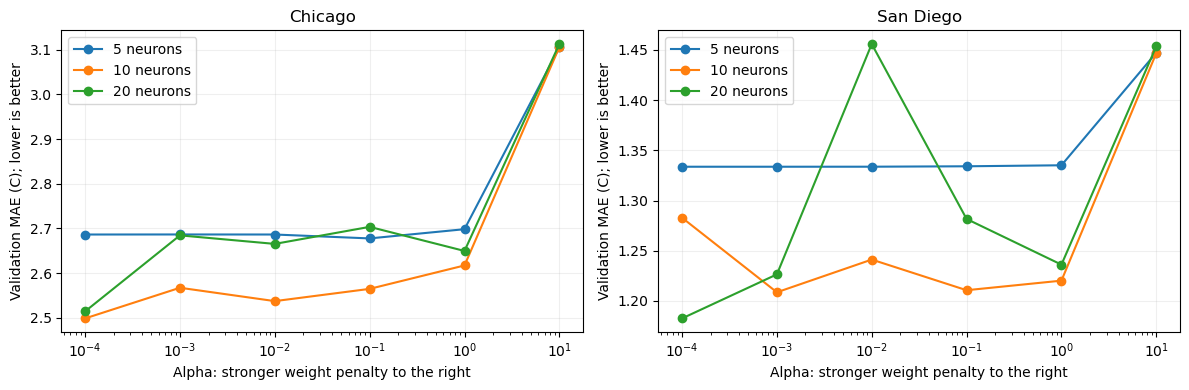

Training: 281 days; validation: 84 days. Only 2009 is used.

 Version      City  Neurons  Alpha  Training MAE (C)  Training RMSE (C)  Training R2  Validation MAE (C)  Validation RMSE (C)  Validation R2  Convergence warning
Original   Chicago        5 0.0001             2.840              3.735        0.878               2.686                3.471          0.900                False
Selected   Chicago        5    0.1             2.839              3.735        0.878               2.677                3.462          0.900                False
Original   Chicago       10 0.0001             2.649              3.512        0.892               2.498                3.257          0.912                False
Selected   Chicago       10 0.0001             2.649              3.512        0.892               2.498                3.257          0.912                False
Original   Chicago       20 0.0001             2.346              3.249        0.907               2.514                3.245    

In [5]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


cities = {
    "Chicago": (41.9, -87.6),
    "San Diego": (32.7, -117.2),
}

widths = [5, 10, 20]
alphas = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]

output = Path("week6_regularization_results")
output.mkdir(exist_ok=True)

all_rows = []
comparison_rows = []
prediction_tables = []

fig, axes = plt.subplots(
    2, 3, figsize=(17, 8), sharex=True, sharey="row"
)

for row, (city, (latitude, longitude)) in enumerate(cities.items()):

    temperature = (
        T2M_C.sel(
            latitude=latitude,
            longitude=longitude,
            method="nearest",
        )
        .sel(valid_time=slice("2009-01-01", "2009-12-31"))
        .to_series()
        .sort_index()
    )

    dates = temperature.index

    if not dates.equals(pd.date_range("2009-01-01", "2009-12-31")):
        raise ValueError("Expected exactly one observation per day in 2009.")

    y = temperature.to_numpy()

    if not np.isfinite(y).all():
        raise ValueError("Temperature contains missing or infinite values.")

    X = dates.dayofyear.to_numpy().reshape(-1, 1)

    # Hold out the final seven calendar days of every month.
    validation_mask = dates.day > dates.days_in_month - 7
    training_mask = ~validation_mask

    assert training_mask.sum() == 281
    assert validation_mask.sum() == 84

    for column, neurons in enumerate(widths):

        candidates = []
        curves = {}

        for alpha in alphas:

            model = TransformedTargetRegressor(
                regressor=make_pipeline(
                    StandardScaler(),
                    MLPRegressor(
                        hidden_layer_sizes=(neurons,),
                        activation="relu",
                        solver="lbfgs",
                        max_iter=5000,
                        max_fun=15000,
                        alpha=alpha,
                        random_state=0,
                    ),
                ),
                transformer=StandardScaler(),
            )

            # Both scalers learn from training data only.
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always", ConvergenceWarning)
                model.fit(X[training_mask], y[training_mask])

            prediction = model.predict(X)
            curves[alpha] = prediction

            scores = {
                "City": city,
                "Neurons": neurons,
                "Alpha": alpha,
            }

            for label, mask in [
                ("Training", training_mask),
                ("Validation", validation_mask),
            ]:
                scores[f"{label} MAE (C)"] = mean_absolute_error(
                    y[mask], prediction[mask]
                )
                scores[f"{label} RMSE (C)"] = np.sqrt(
                    mean_squared_error(y[mask], prediction[mask])
                )
                scores[f"{label} R2"] = r2_score(
                    y[mask], prediction[mask]
                )

            scores["Convergence warning"] = any(
                issubclass(w.category, ConvergenceWarning)
                for w in caught
            )
            candidates.append(scores)

            for warning in caught:
                print(
                    f"Fit warning: {city}, {neurons} neurons, "
                    f"alpha {alpha}: {warning.message}"
                )

            prediction_tables.append(pd.DataFrame({
                "Date": dates,
                "City": city,
                "Neurons": neurons,
                "Alpha": alpha,
                "Split": np.where(
                    validation_mask, "Validation", "Training"
                ),
                "Actual (C)": y,
                "Predicted (C)": prediction,
            }))

        candidates = pd.DataFrame(candidates)

        # Select alpha using validation MAE, including the original setting.
        best = candidates.loc[
            candidates["Validation MAE (C)"].idxmin()
        ]
        best_alpha = float(best["Alpha"])

        all_rows.extend(candidates.to_dict("records"))

        comparison_rows.append({
            "Version": "Original",
            **candidates.iloc[0].to_dict(),
        })
        comparison_rows.append({
            "Version": "Selected",
            **best.to_dict(),
        })

        ax = axes[row, column]

        ax.scatter(
            dates[training_mask], y[training_mask],
            color="gray", s=9, alpha=0.25,
            label="Training data",
        )
        ax.scatter(
            dates[validation_mask], y[validation_mask],
            color="black", s=15, alpha=0.65,
            label="Validation data",
        )
        ax.plot(
            dates, curves[alphas[0]],
            color="tab:orange", linestyle="--",
            label="Original alpha=0.0001",
        )
        ax.plot(
            dates, curves[best_alpha],
            color="tab:blue",
            label=f"Selected alpha={best_alpha:g}",
        )

        ax.set_title(f"{city}: {neurons} neurons")
        ax.set_ylabel("Temperature (C)")
        ax.set_xlabel("Month in 2009")
        ax.set_xlim(dates[0], dates[-1])
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        ax.grid(alpha=0.2)
        ax.legend(fontsize=7)


regularization_scores = pd.DataFrame(all_rows)
regularization_comparison = pd.DataFrame(comparison_rows)
regularization_predictions = pd.concat(
    prediction_tables, ignore_index=True
)

regularization_scores.to_csv(
    output / "all_scores.csv", index=False
)
regularization_comparison.to_csv(
    output / "comparison.csv", index=False
)
regularization_predictions.to_csv(
    output / "predictions.csv", index=False
)

fig.suptitle(
    "Week 6 L2 regularization: original versus validation-selected alpha"
)
fig.tight_layout()
fig.savefig(output / "seasonal_comparison.png", dpi=150)

if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)


# Compare validation error across penalty strengths.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, city in zip(axes, cities):

    for neurons in widths:
        scores = regularization_scores.query(
            "City == @city and Neurons == @neurons"
        )

        ax.plot(
            scores["Alpha"],
            scores["Validation MAE (C)"],
            marker="o",
            label=f"{neurons} neurons",
        )

    ax.set_xscale("log")
    ax.set_title(city)
    ax.set_xlabel("Alpha: stronger weight penalty to the right")
    ax.set_ylabel("Validation MAE (C); lower is better")
    ax.grid(alpha=0.2)
    ax.legend()

fig.tight_layout()
fig.savefig(output / "alpha_validation_mae.png", dpi=150)

if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)


print("Training: 281 days; validation: 84 days. Only 2009 is used.\n")

display_scores = regularization_comparison.copy()
display_scores["Alpha"] = display_scores["Alpha"].map(
    lambda value: f"{value:g}"
)
print(display_scores.round(3).to_string(index=False))

print("\nAll validation MAEs:")
print(
    regularization_scores.pivot(
        index=["City", "Neurons"],
        columns="Alpha",
        values="Validation MAE (C)",
    ).round(3).to_string()
)

“My original question was whether adding more neurons improves temperature predictions. This experiment asks something different: can stronger regularization improve a network without making it larger? Regularization penalizes large weights and can reduce overfitting.

We trained on 281 days from 2009 and held out the final seven days of each month, giving us 84 validation days. The only input was day of year.

The clearest improvement was San Diego’s 10-neuron network. Its average absolute validation error decreased from 1.28 to 1.21 degrees Celsius, about 6%. Its training error increased slightly, showing that fitting training data better does not always mean predicting held-out data better.

However, Chicago showed little improvement, and the original best models still had the lowest error overall.

The main limitations are that we used one year, one initialization for the regularization comparison, and no weather inputs beyond the calendar. We also selected the penalty using validation data, so the improvement still needs checking on independent data before making forecasting claims.”

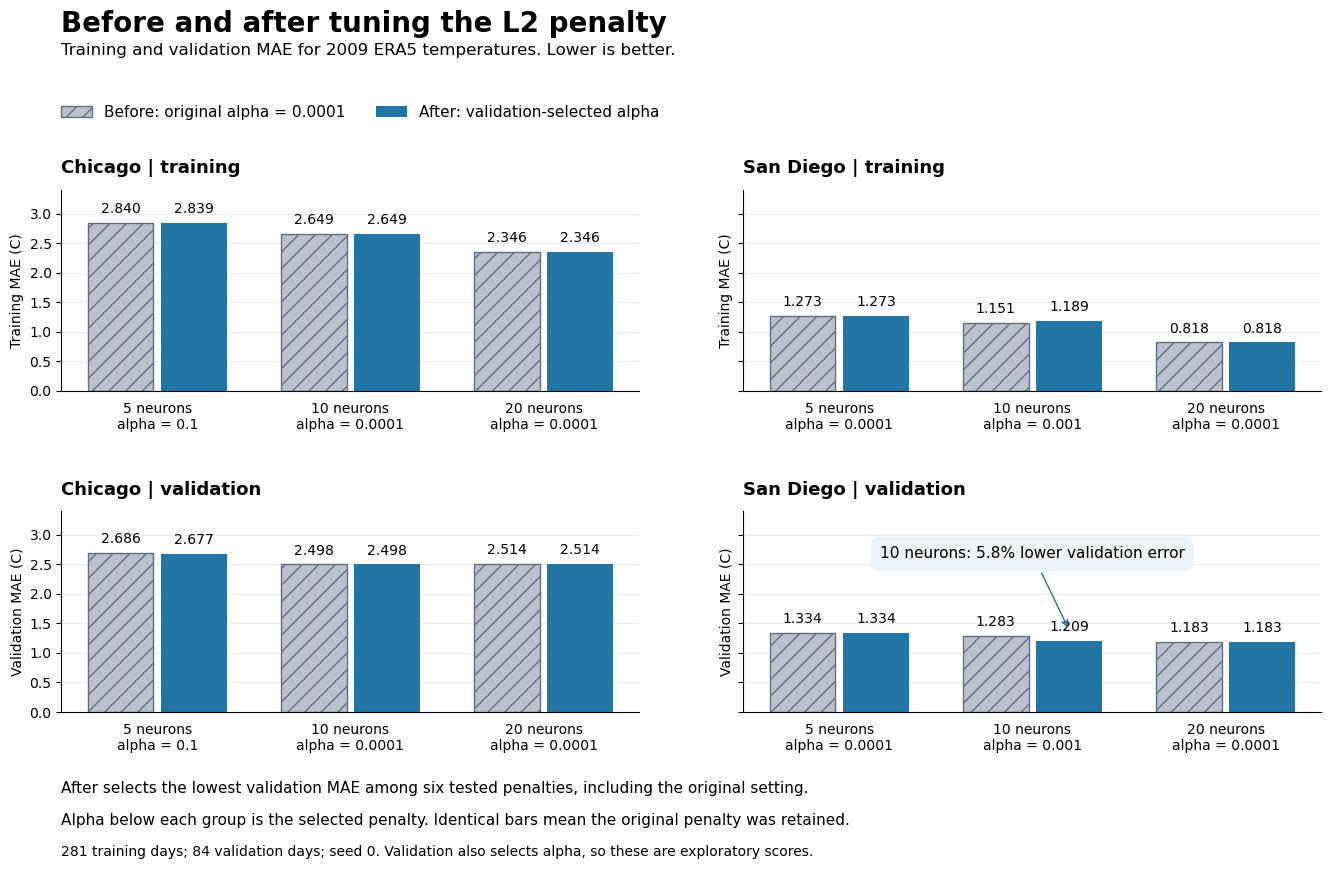

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


output_dir = Path(
    "/Users/amirsh96/290A/Project 1/week6_regularization_results"
)

comparison_file = output_dir / "comparison.csv"

if not comparison_file.exists():
    raise FileNotFoundError(
        "Run the L2 regularization experiment first to create comparison.csv."
    )

comparison = pd.read_csv(comparison_file)

cities = ["Chicago", "San Diego"]
widths = [5, 10, 20]

before_color = "#B9C2CC"
after_color = "#2375A6"

fig, axes = plt.subplots(
    2, 2, figsize=(14, 9), sharey=True
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.78,
    bottom=0.20,
    wspace=0.18,
    hspace=0.60,
)

for column, city in enumerate(cities):

    before = comparison[
        (comparison["City"] == city)
        & (comparison["Version"] == "Original")
    ].set_index("Neurons").loc[widths]

    after = comparison[
        (comparison["City"] == city)
        & (comparison["Version"] == "Selected")
    ].set_index("Neurons").loc[widths]

    positions = np.arange(len(widths))

    for row, split in enumerate(["Training", "Validation"]):

        ax = axes[row, column]
        metric = f"{split} MAE (C)"

        before_bars = ax.bar(
            positions - 0.19,
            before[metric],
            width=0.34,
            color=before_color,
            edgecolor="#617080",
            hatch="//",
            label="Before: original alpha = 0.0001",
        )

        after_bars = ax.bar(
            positions + 0.19,
            after[metric],
            width=0.34,
            color=after_color,
            label="After: validation-selected alpha",
        )

        ax.bar_label(
            before_bars,
            fmt="%.3f",
            padding=5,
            fontsize=10,
        )

        ax.bar_label(
            after_bars,
            fmt="%.3f",
            padding=5,
            fontsize=10,
        )

        ax.set_xticks(
            positions,
            [
                f"{neurons} neurons\nalpha = {alpha:g}"
                for neurons, alpha in zip(widths, after["Alpha"])
            ],
        )

        ax.set_title(
            f"{city} | {split.lower()}",
            fontsize=13,
            fontweight="bold",
            loc="left",
            pad=12,
        )

        ax.set_ylabel(f"{split} MAE (C)")
        ax.set_ylim(0, 3.4)
        ax.set_yticks(np.arange(0, 3.1, 0.5))

        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(axis="x", length=0, pad=8)


# Calculate the improvement for San Diego's 10-neuron model.
san_diego_10 = comparison[
    (comparison["City"] == "San Diego")
    & (comparison["Neurons"] == 10)
].set_index("Version")

before_mae = san_diego_10.loc[
    "Original", "Validation MAE (C)"
]

after_mae = san_diego_10.loc[
    "Selected", "Validation MAE (C)"
]

improvement = 100 * (before_mae - after_mae) / before_mae

axes[1, 1].annotate(
    f"10 neurons: {improvement:.1f}% lower validation error",
    xy=(1.19, after_mae + 0.18),
    xytext=(1.0, 2.6),
    ha="center",
    fontsize=11,
    bbox={
        "boxstyle": "round,pad=0.6",
        "facecolor": "#EAF3F8",
        "edgecolor": "none",
    },
    arrowprops={
        "arrowstyle": "->",
        "color": after_color,
    },
)

fig.suptitle(
    "Before and after tuning the L2 penalty",
    x=0.08,
    y=0.98,
    ha="left",
    fontsize=20,
    fontweight="bold",
)

fig.text(
    0.08,
    0.93,
    "Training and validation MAE for 2009 ERA5 temperatures. "
    "Lower is better.",
    fontsize=12,
)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper left",
    bbox_to_anchor=(0.07, 0.89),
    ncol=2,
    frameon=False,
    fontsize=11,
)

fig.text(
    0.08,
    0.11,
    "After selects the lowest validation MAE among six tested penalties, "
    "including the original setting.",
    fontsize=11,
)

fig.text(
    0.08,
    0.075,
    "Alpha below each group is the selected penalty. "
    "Identical bars mean the original penalty was retained.",
    fontsize=11,
)

fig.text(
    0.08,
    0.04,
    "281 training days; 84 validation days; seed 0. "
    "Validation also selects alpha, so these are exploratory scores.",
    fontsize=10,
)

fig.savefig(
    output_dir / "before_after_l2.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

San Diego, 10 neurons: validation error fell from 1.283°C to 1.209°C, a 5.8% improvement, while training error increased slightly.
Chicago improved negligibly. Four models stayed unchanged, and the original best models still had the lowest overall validation MAE.

Limitations: One year, one initialization, and only day of year as input. Validation data also selected the penalty, so the gain needs independent testing. Future forecasting accuracy remains untested.

Video presentation: https://docs.google.com/videos/u/0/d/1S5Nh2gUmm-7bIDSSCVMxLXWdoGhODzroPLY48qjKS14/play?usp=chrome_extension_sharing
